Objectives
1. Understand how TF-IDF works.
2. Build separate TF-IDF representations for different TED Talk text fields.
3. Experiment with vectorisation parameters.
4. Compare vocabulary size and matrix sparsity.
5. Combine the text representations using feature weights.
6. Save trained vectorisers and sparse feature matrices.
Skills: Scikit-learn, TF-IDF, sparse matrices, feature weighting, model persistence and numerical analysis.
2. Why separate vectorisers?
Rather than combining all fields into one large text column, we'll vectorise each field separately.
Text feature	Starting weight	Reason
Title	2.0	Central topic
Description	1.5	Summary of the talk
Tags	1.5	Topic categories
Transcript	1.0	Detailed content

These are initial experimental weights, not proven optimal values. We will evaluate them later.
3. Import libraries

In [1]:
pip install pandas numpy scikit-learn scipy joblib matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import json
import joblib

from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, save_npz, load_npz

from sklearn.preprocessing import normalize

pd.set_option("display.max_columns", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Automatically locate the project root
PROJECT_ROOT = Path.cwd().resolve()

while PROJECT_ROOT != PROJECT_ROOT.parent:

    required_file = (
        PROJECT_ROOT /
        "Module_3_Feature_Engineering_Vectorization" /
        "features" /
        "ted_talks_features.csv"
    )

    if required_file.exists():
        break

    PROJECT_ROOT = PROJECT_ROOT.parent

if not required_file.exists():

    raise FileNotFoundError(
        "Feature dataset not found. "
        "Run Notebook 01 first."
    )


# Input
INPUT_PATH = required_file

# Module 3 directories
MODULE_DIR = (
    PROJECT_ROOT /
    "Module_3_Feature_Engineering_Vectorization"
)

MODEL_DIR = MODULE_DIR / "models"

FEATURE_DIR = MODULE_DIR / "features"

OUTPUT_DIR = MODULE_DIR / "outputs"

REPORT_DIR = OUTPUT_DIR / "reports"

STATISTICS_DIR = OUTPUT_DIR / "statistics"


# Create directories
for folder in [
    MODEL_DIR,
    FEATURE_DIR,
    REPORT_DIR,
    STATISTICS_DIR
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


print("Project root:", PROJECT_ROOT)
print("Input:", INPUT_PATH)
print("Model directory:", MODEL_DIR)

Project root: C:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation
Input: C:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_3_Feature_Engineering_Vectorization\features\ted_talks_features.csv
Model directory: C:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_3_Feature_Engineering_Vectorization\models


In [4]:
df = pd.read_csv(
    INPUT_PATH,
    low_memory=False
)

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (1866, 60)

Available columns:
['talk_id', 'title', 'main_speaker', 'speaker_occupation', 'description', 'tags', 'transcript', 'related_talks', 'ratings', 'views', 'comments', 'duration', 'published_date', 'event', 'url', 'source', 'film_date', 'languages', 'name', 'num_speaker', 'tags_list', 'tag_count', 'tags_text', 'title_clean', 'description_clean', 'transcript_clean', 'speaker_clean', 'published_datetime', 'published_year', 'published_month', 'duration_minutes', 'title_word_count', 'title_char_count', 'description_word_count', 'description_char_count', 'transcript_word_count', 'transcript_char_count', 'has_transcript', 'has_description', 'has_tags', 'content_field_count', 'content_text', 'content_word_count', 'title_processed', 'description_processed', 'tags_processed', 'transcript_processed', 'combined_text', 'content_text_fallback', 'uses_fallback', 'title_processed_word_count', 'title_processed_char_count', 'description_processed_word_count', 'description_process

,talk_id,title,main_speaker,speaker_occupation,description,tags,transcript,related_talks,ratings,views,comments,duration,published_date,event,url,source,film_date,languages,name,num_speaker,tags_list,tag_count,tags_text,title_clean,description_clean,transcript_clean,speaker_clean,published_datetime,published_year,published_month,duration_minutes,title_word_count,title_char_count,description_word_count,description_char_count,transcript_word_count,transcript_char_count,has_transcript,has_description,has_tags,content_field_count,content_text,content_word_count,title_processed,description_processed,tags_processed,transcript_processed,combined_text,content_text_fallback,uses_fallback,title_processed_word_count,title_processed_char_count,description_processed_word_count,description_processed_char_count,tags_processed_word_count,tags_processed_char_count,transcript_processed_word_count,transcript_processed_char_count,combined_text_word_count,combined_text_char_count
0,1,Do schools kill creativity?,Ken Robinson,Author/educator,Sir Ken Robinson makes an entertaining and pro...,"['children', 'creativity', 'culture', 'dance',...",Good morning. How are you?(Laughter)It's been ...,"[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...","[{'id': 7, 'name': 'Funny', 'count': 19645}, {...",47227110,4553,1164,1151367060,TED2006,https://www.ted.com/talks/ken_robinson_says_sc...,TED_Public_Archive_CC_BY_NC_SA_4.0,1140825600,60,Ken Robinson: Do schools kill creativity?,1,"[""children"", ""creativity"", ""culture"", ""dance"",...",7,children creativity culture dance education pa...,do schools kill creativity,sir ken robinson makes an entertaining and pro...,good morning how are you laughter it's been gr...,ken robinson,2006-06-27 00:11:00+00:00,2006,6,19.40,4,26,21,146,3163,16800,True,True,True,4,do schools kill creativity sir ken robinson ma...,3197,do schools kill creativity?,sir ken robinson makes an entertaining and pro...,"['children', 'creativity', 'culture', 'dance',...",good morning. how are you?(laughter)it's been ...,do schools kill creativity? sir ken robinson m...,do schools kill creativity? sir ken robinson m...,False,4,27,21,149,7,84,3066,17409,3098,17672
1,2,Averting the climate crisis,Al Gore,Climate advocate,With the same humor and humanity he exuded in ...,"['alternative energy', 'cars', 'climate change...","Thank you so much, Chris. And it's truly a gre...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...","[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...",3200520,265,977,1151367060,TED2006,https://www.ted.com/talks/al_gore_on_averting_...,TED_Public_Archive_CC_BY_NC_SA_4.0,1140825600,43,Al Gore: Averting the climate crisis,1,"[""alternative energy"", ""cars"", ""climate change...",9,alternative energy cars climate change culture...,averting the climate crisis,with the same humor and humanity he exuded in ...,thank you so much chris and it's truly a great...,al gore,2006-06-27 00:11:00+00:00,2006,6,16.28,4,27,39,227,2155,11461,True,True,True,4,averting the climate crisis with the same humo...,2212,averting the climate crisis,with the same humor and humanity he exuded in ...,"['alternative energy', 'cars', 'climate change...","thank you so much, chris. and it's truly a gre...",averting the climate crisis with the same humo...,averting the climate crisis with the same humo...,False,4,27,39,233,12,134,2089,11814,2144,12211
2,3,Simplicity sells,David Pogue,Technology columnist,New York Times columnist David Pogue takes aim...,"['computers', 'entertainment', 'interface desi...","(Music: ""The Sound of Silence,"" Simon & Garfun...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...","[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...",1636292,124,1286,1151367060,TED2006,https://www.ted.com/talks/david_pogue_says_sim...,TED_Public_Archive_CC_BY_NC_SA_4.0,1140739200,26,David Pogue: Simplicity sells,1,"[""computers"", ""entertainment"", ""interface desi...",9,computers entertainment interface design media...,simplicity sells,new york times

In [5]:
required_columns = [
    "title_processed",
    "description_processed",
    "tags_processed",
    "transcript_processed"
]

for column in required_columns:

    if column not in df.columns:

        raise ValueError(
            f"Required column missing: {column}"
        )

    print(
        column,
        "->",
        "Available"
    )

title_processed -> Available
description_processed -> Available
tags_processed -> Available
transcript_processed -> Available


In [6]:
TFIDF_CONFIG = {

    "max_features": 30000,

    "ngram_range": (1, 2),

    "min_df": 2,

    "max_df": 0.90,

    "sublinear_tf": True,

    "stop_words": "english",

    "dtype": np.float32

}

print("TF-IDF configuration:")

for key, value in TFIDF_CONFIG.items():

    print(f"{key}: {value}")

TF-IDF configuration:
max_features: 30000
ngram_range: (1, 2)
min_df: 2
max_df: 0.9
sublinear_tf: True
stop_words: english
dtype: <class 'numpy.float32'>


In [7]:
TEXT_FIELDS = {

    "title": "title_processed",

    "description": "description_processed",

    "tags": "tags_processed",

    "transcript": "transcript_processed"

}

vectorizers = {}

tfidf_matrices = {}

feature_statistics = []

for feature_name, column_name in TEXT_FIELDS.items():

    print(f"\nProcessing: {feature_name}")

    # Ensure missing values are empty strings
    documents = (
        df[column_name]
        .fillna("")
        .astype(str)
    )

    # Create vectoriser
    vectorizer = TfidfVectorizer(
        **TFIDF_CONFIG
    )

    # Fit and transform documents
    matrix = vectorizer.fit_transform(
        documents
    )

    # Save vectoriser and matrix in memory
    vectorizers[feature_name] = vectorizer

    tfidf_matrices[feature_name] = matrix

    # Calculate statistics
    vocabulary_size = len(
        vectorizer.vocabulary_
    )

    total_elements = (
        matrix.shape[0] * matrix.shape[1]
    )

    sparsity = (
        1 - matrix.nnz / total_elements
    ) * 100 if total_elements else 0

    feature_statistics.append({

        "Feature": feature_name,

        "Documents": matrix.shape[0],

        "Vocabulary Size": vocabulary_size,

        "Matrix Rows": matrix.shape[0],

        "Matrix Columns": matrix.shape[1],

        "Non-zero Elements": matrix.nnz,

        "Sparsity Percentage": round(
            sparsity,
            2
        )

    })

    print("Matrix shape:", matrix.shape)

    print("Vocabulary size:", vocabulary_size)

    print("Non-zero values:", matrix.nnz)

print("\nAll vectorisers completed!")


Processing: title
Matrix shape: (1866, 1104)
Vocabulary size: 1104
Non-zero values: 4599

Processing: description
Matrix shape: (1866, 7414)
Vocabulary size: 7414
Non-zero values: 44363

Processing: tags
Matrix shape: (1866, 2077)
Vocabulary size: 2077
Non-zero values: 22474

Processing: transcript
Matrix shape: (1866, 30000)
Vocabulary size: 30000
Non-zero values: 1005976

All vectorisers completed!


In [8]:
statistics_df = pd.DataFrame(
    feature_statistics
)

display(statistics_df)

,Feature,Documents,Vocabulary Size,Matrix Rows,Matrix Columns,Non-zero Elements,Sparsity Percentage
0,title,1866,1104,1866,1104,4599,99.78
1,description,1866,7414,1866,7414,44363,99.68
2,tags,1866,2077,1866,2077,22474,99.42
3,transcript,1866,30000,1866,30000,1005976,98.20


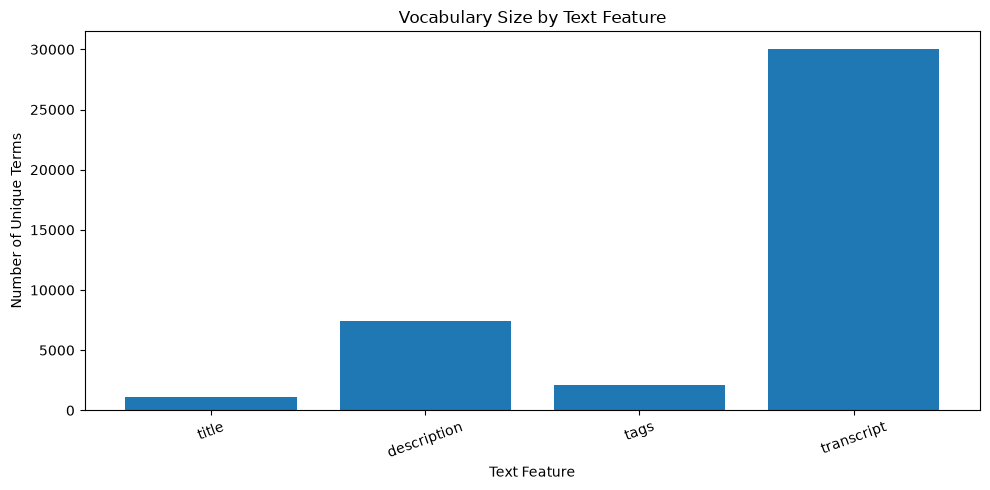

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    statistics_df["Feature"],
    statistics_df["Vocabulary Size"]
)

plt.title("Vocabulary Size by Text Feature")

plt.xlabel("Text Feature")

plt.ylabel("Number of Unique Terms")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [10]:
FIELD_WEIGHTS = {

    "title": 2.0,

    "description": 1.5,

    "tags": 1.5,

    "transcript": 1.0

}

In [11]:
weighted_matrices = []

for feature_name in TEXT_FIELDS:

    matrix = tfidf_matrices[feature_name]

    weight = FIELD_WEIGHTS[feature_name]

    weighted_matrix = matrix.multiply(
        weight
    )

    weighted_matrices.append(
        weighted_matrix
    )


# Combine all feature matrices
combined_matrix = hstack(
    weighted_matrices,
    format="csr"
)

# L2-normalise each talk's combined feature vector
combined_matrix = normalize(
    combined_matrix,
    norm="l2",
    axis=1
).tocsr()


print("Combined TF-IDF matrix created!")

print("Shape:", combined_matrix.shape)

print("Non-zero elements:", combined_matrix.nnz)

Combined TF-IDF matrix created!
Shape: (1866, 40595)
Non-zero elements: 1077412


In [12]:
def get_top_terms(
    vectorizer,
    matrix,
    document_index,
    top_n=15
):

    feature_names = np.array(
        vectorizer.get_feature_names_out()
    )

    row = matrix.getrow(
        document_index
    )

    if row.nnz == 0:
        return pd.DataFrame(
            columns=["Term", "TF-IDF Score"]
        )

    indices = np.argsort(
        row.data
    )[::-1][:top_n]

    top_indices = row.indices[indices]

    top_scores = row.data[indices]

    return pd.DataFrame({

        "Term": feature_names[top_indices],

        "TF-IDF Score": top_scores

    })


# Inspect the first TED Talk
top_terms = get_top_terms(
    vectorizers["transcript"],
    tfidf_matrices["transcript"],
    document_index=0,
    top_n=15
)

display(top_terms)

,Term,TF-IDF Score
0,gillian,0.139441
1,ballet,0.096582
2,public education,0.091556
3,capacities,0.091039
4,shakespeare,0.086523
5,royal,0.078221
6,educating,0.074427
7,education world,0.073867
8,say work,0.073867
9,education,0.073735


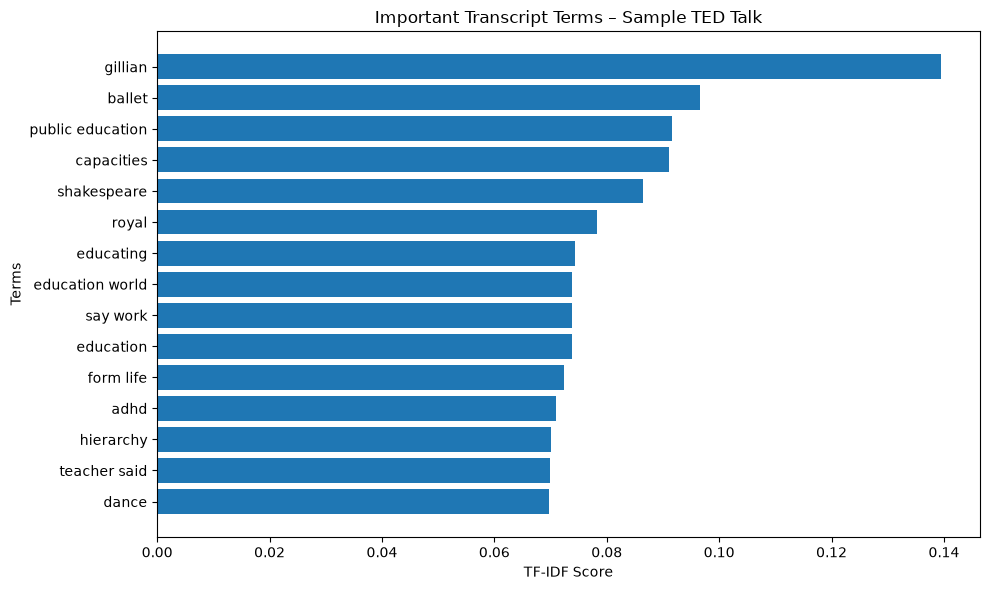

In [13]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_terms["Term"][::-1],
    top_terms["TF-IDF Score"][::-1]
)

plt.title("Important Transcript Terms – Sample TED Talk")

plt.xlabel("TF-IDF Score")

plt.ylabel("Terms")

plt.tight_layout()

plt.show()

In [14]:
# Save individual vectorisers
for feature_name, vectorizer in vectorizers.items():

    model_path = (
        MODEL_DIR /
        f"{feature_name}_tfidf_vectorizer.joblib"
    )

    joblib.dump(
        vectorizer,
        model_path
    )

    print("Saved:", model_path.name)

Saved: title_tfidf_vectorizer.joblib
Saved: description_tfidf_vectorizer.joblib
Saved: tags_tfidf_vectorizer.joblib
Saved: transcript_tfidf_vectorizer.joblib


In [15]:
COMBINED_MATRIX_PATH = (
    FEATURE_DIR /
    "combined_tfidf_matrix.npz"
)

save_npz(
    COMBINED_MATRIX_PATH,
    combined_matrix
)

print("Combined matrix saved!")

Combined matrix saved!


In [16]:
print("MODULE 3 - NOTEBOOK 02 VERIFICATION")

files_to_check = [

    MODEL_DIR / "title_tfidf_vectorizer.joblib",

    MODEL_DIR / "description_tfidf_vectorizer.joblib",

    MODEL_DIR / "tags_tfidf_vectorizer.joblib",

    MODEL_DIR / "transcript_tfidf_vectorizer.joblib",

    FEATURE_DIR / "combined_tfidf_matrix.npz",

    REPORT_DIR / "tfidf_configuration.json",

    STATISTICS_DIR / "tfidf_statistics.csv"

]

for file in files_to_check:

    print(
        file.name,
        "->",
        "SAVED" if file.exists() else "MISSING"
    )

MODULE 3 - NOTEBOOK 02 VERIFICATION
title_tfidf_vectorizer.joblib -> SAVED
description_tfidf_vectorizer.joblib -> SAVED
tags_tfidf_vectorizer.joblib -> SAVED
transcript_tfidf_vectorizer.joblib -> SAVED
combined_tfidf_matrix.npz -> SAVED
tfidf_configuration.json -> MISSING
tfidf_statistics.csv -> MISSING
